## Importing Required Libraries

In [1]:
import pandas as pd
import numpy as np
import xml.etree.ElementTree as ET

## Loading the CPI data 

In [2]:
df1 = pd.read_csv(r"D:\New folder\OECD.SDD.TPS,DSD_PRICES@DF_PRICES_ALL,+IND+DEU.M.N.CPI.._T.N.GY+_Z.csv")

In [3]:
cpi_data = df1.groupby(['TIME_PERIOD', 'Reference area'])['OBS_VALUE'].mean().unstack() #using groupby to filter only the required coulumns

In [4]:
cpi_data.rename(columns={'India': 'CPI_India', 'Germany': 'CPI_Germany'}, inplace=True)

In [5]:
cpi_data.index = pd.to_datetime(cpi_data.index)
cpi_data = cpi_data.sort_index()

### Final CPI data

In [6]:
cpi_data

Reference area,CPI_Germany,CPI_India
TIME_PERIOD,,
2015-01-01,49.116567,52.167948
2015-02-01,49.584988,51.541441
2015-03-01,49.945703,51.719525
2015-04-01,50.541466,51.856542
2015-05-01,50.789625,52.215363
...,...,...
2024-10-01,64.381125,81.805907
2024-11-01,64.312570,81.543200
2024-12-01,64.840873,80.926580


## Exchange data downloaded from ECB's site

In [7]:
tree = ET.parse(r"D:\New folder\Exchange_Rate_Ind.Ger.xml")# parsing the XML format to make use of the data
root = tree.getroot()
ns = {'ns': 'http://www.ecb.europa.eu/vocabulary/stats/exr/1'}
data = []
for obs in root.findall('.//ns:Obs', ns):
    date = obs.attrib['TIME_PERIOD']
    value = obs.attrib['OBS_VALUE']
    data.append((date, float(value)))

In [8]:
fx_df = pd.DataFrame(data, columns=['Date', 'Exchange_Rate_INR_per_EUR'])
fx_df['Date'] = pd.to_datetime(fx_df['Date'])
fx_df.set_index('Date', inplace=True)
fx_monthly = fx_df.resample('MS').mean()

### Final exchange data extracted

In [9]:
fx_monthly

,Exchange_Rate_INR_per_EUR
Date,
2009-01-01,64.510381
2009-02-01,62.884890
2009-03-01,66.802641
2009-04-01,66.047100
2009-05-01,66.176165
...,...
2024-12-01,89.045290
2025-01-01,89.341750
2025-02-01,90.634640


## Merging CPI data and exchange rate data

In [10]:
df2 = cpi_data.merge(fx_monthly, left_index=True, right_index=True, how='inner')

In [11]:
df2.isna().sum()

CPI_Germany                  0
CPI_India                    0
Exchange_Rate_INR_per_EUR    0
dtype: int64

### Calculated Real Exchange Rate (RER)

In [12]:
df2['RER'] = (df2['Exchange_Rate_INR_per_EUR'] * df2['CPI_Germany']) / df2['CPI_India']

In [13]:
df2

,CPI_Germany,CPI_India,Exchange_Rate_INR_per_EUR,RER
2015-01-01,49.116567,52.167948,72.214086,67.990176
2015-02-01,49.584988,51.541441,70.435630,67.761977
2015-03-01,49.945703,51.719525,67.738723,65.415491
2015-04-01,50.541466,51.856542,67.643190,65.927767
2015-05-01,50.789625,52.215363,71.115300,69.173501
...,...,...,...,...
2024-10-01,64.381125,81.805907,91.626622,72.110013
2024-11-01,64.312570,81.543200,89.671714,70.723474
2024-12-01,64.840873,80.926580,89.045290,71.345834
2025-01-01,64.563159,80.433876,89.341750,71.713386


In [14]:
df2.isna().sum()

CPI_Germany                  0
CPI_India                    0
Exchange_Rate_INR_per_EUR    0
RER                          0
dtype: int64

## Applying Log transformations

In [15]:
df2['log_CPI_India'] = np.log(df2['CPI_India'])
df2['log_CPI_Germany'] = np.log(df2['CPI_Germany'])
df2['log_NER'] = np.log(df2['Exchange_Rate_INR_per_EUR'])
df2['log_RER'] = np.log(df2['RER'])

In [16]:
df2

,CPI_Germany,CPI_India,Exchange_Rate_INR_per_EUR,RER,log_CPI_India,log_CPI_Germany,log_NER,log_RER
2015-01-01,49.116567,52.167948,72.214086,67.990176,3.954468,3.894196,4.279635,4.219363
2015-02-01,49.584988,51.541441,70.435630,67.761977,3.942386,3.903688,4.254699,4.216001
2015-03-01,49.945703,51.719525,67.738723,65.415491,3.945835,3.910936,4.215658,4.180759
2015-04-01,50.541466,51.856542,67.643190,65.927767,3.948481,3.922794,4.214247,4.188560
2015-05-01,50.789625,52.215363,71.115300,69.173501,3.955377,3.927692,4.264303,4.236618
...,...,...,...,...,...,...,...,...
2024-10-01,64.381125,81.805907,91.626622,72.110013,4.404349,4.164821,4.517722,4.278193
2024-11-01,64.312570,81.543200,89.671714,70.723474,4.401133,4.163755,4.496155,4.258778
2024-12-01,64.840873,80.926580,89.045290,71.345834,4.393542,4.171936,4.489145,4.267539
2025-01-01,64.563159,80.433876,89.341750,71.713386,4.387435,4.167644,4.492469,4.272677


## Importing additional libraries for analysis

In [17]:
from statsmodels.tsa.stattools import adfuller, kpss
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.graphics.gofplots import qqplot

## Analyzing all the 4 columns on rolling stats, ACF, PACF, histogram and Q-Q plot

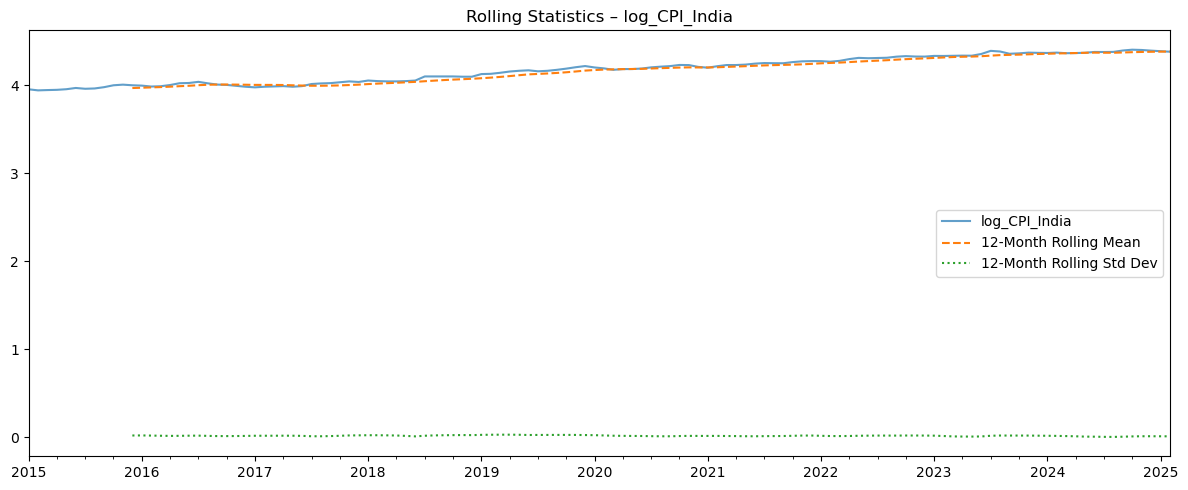

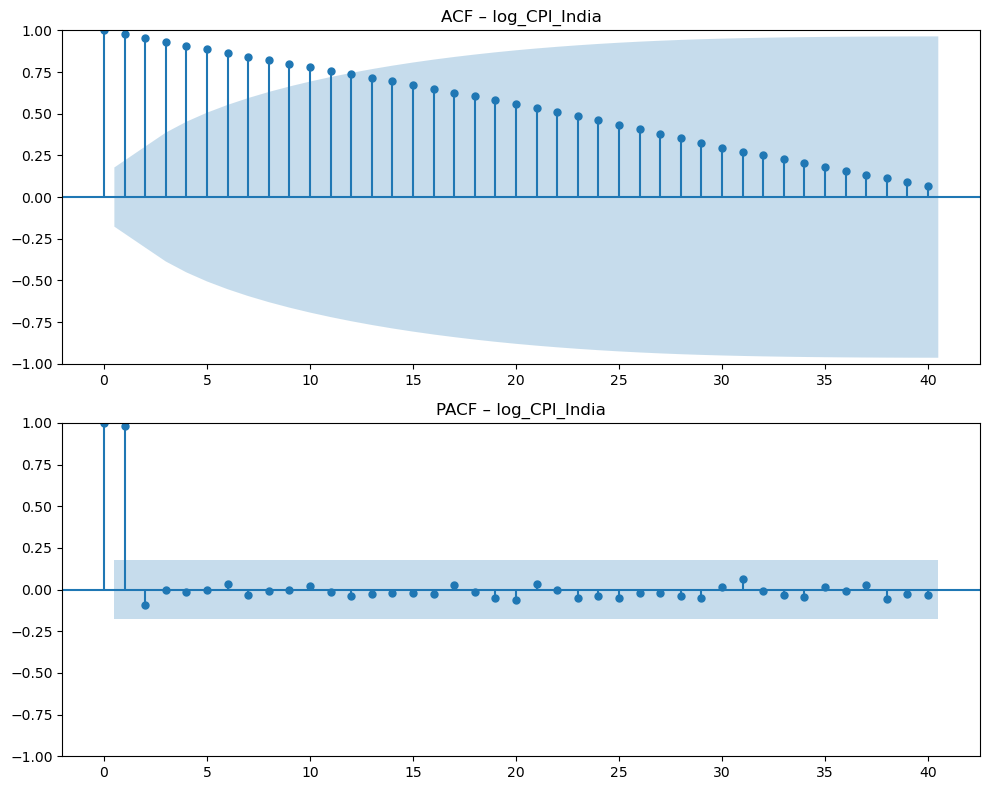

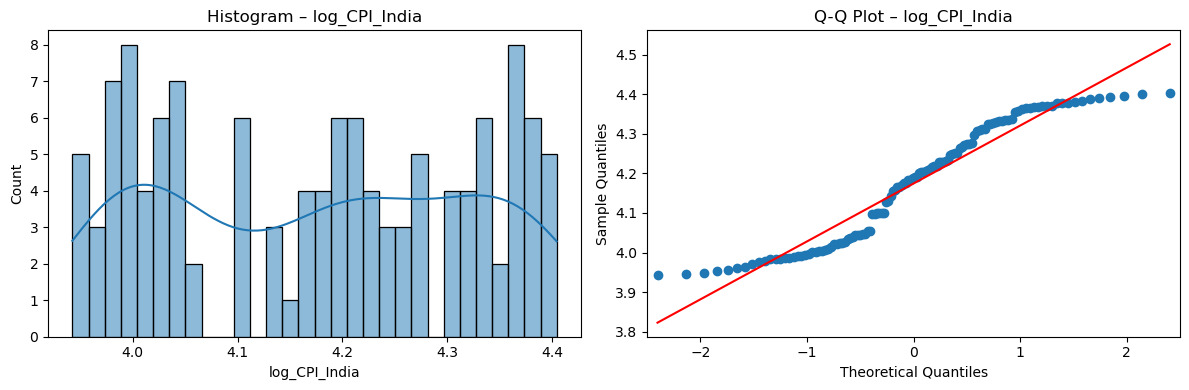

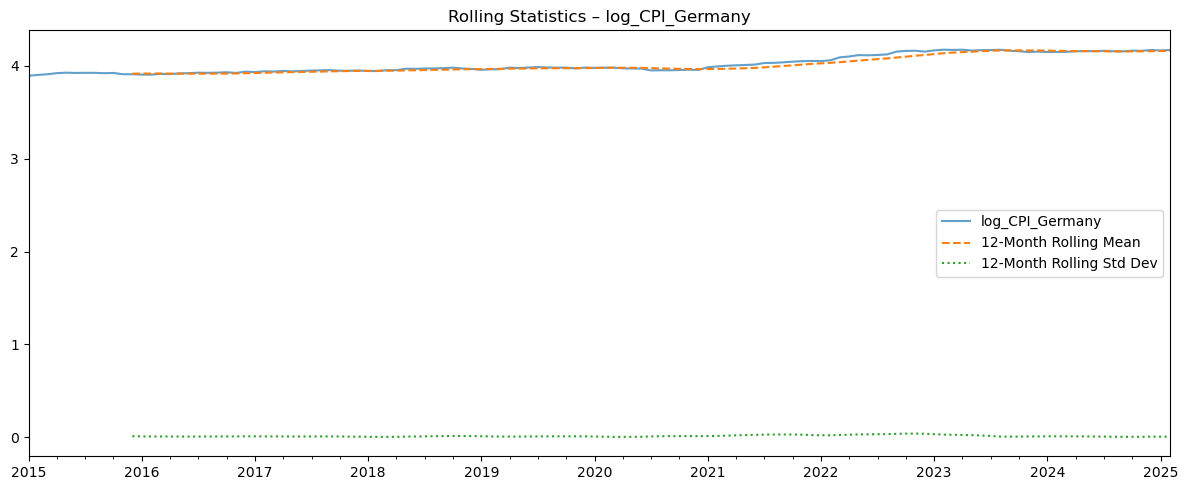

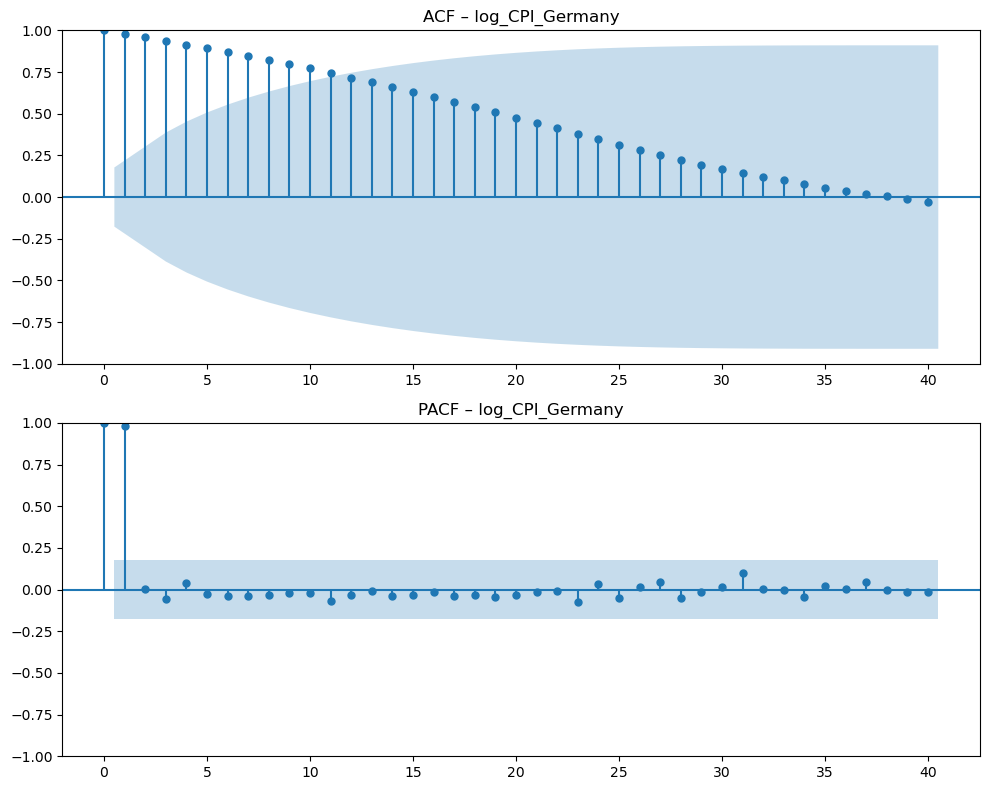

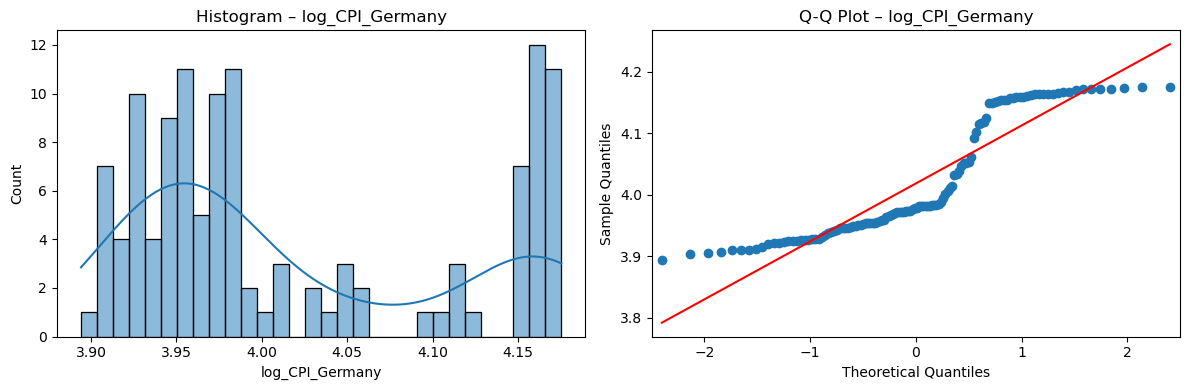

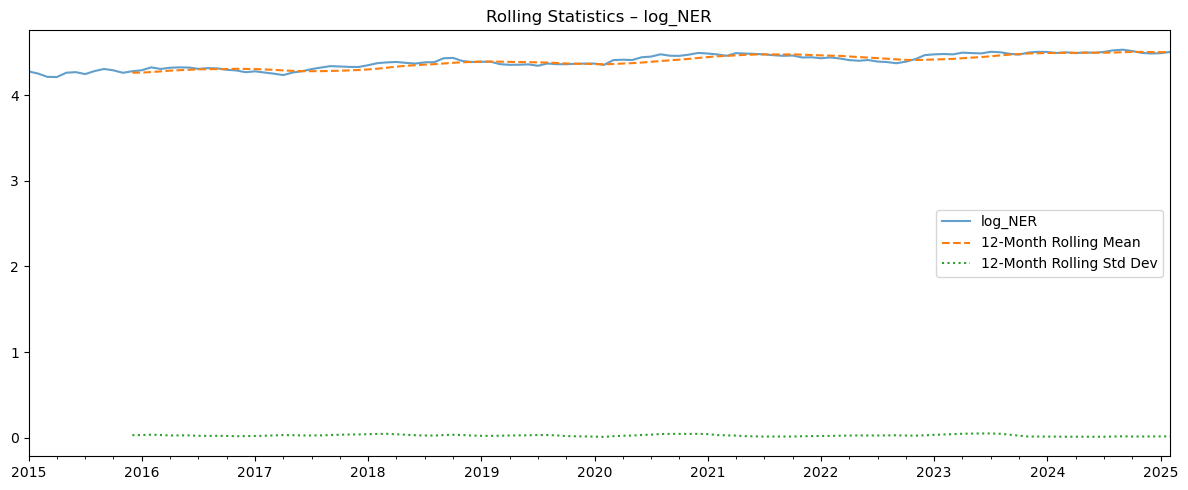

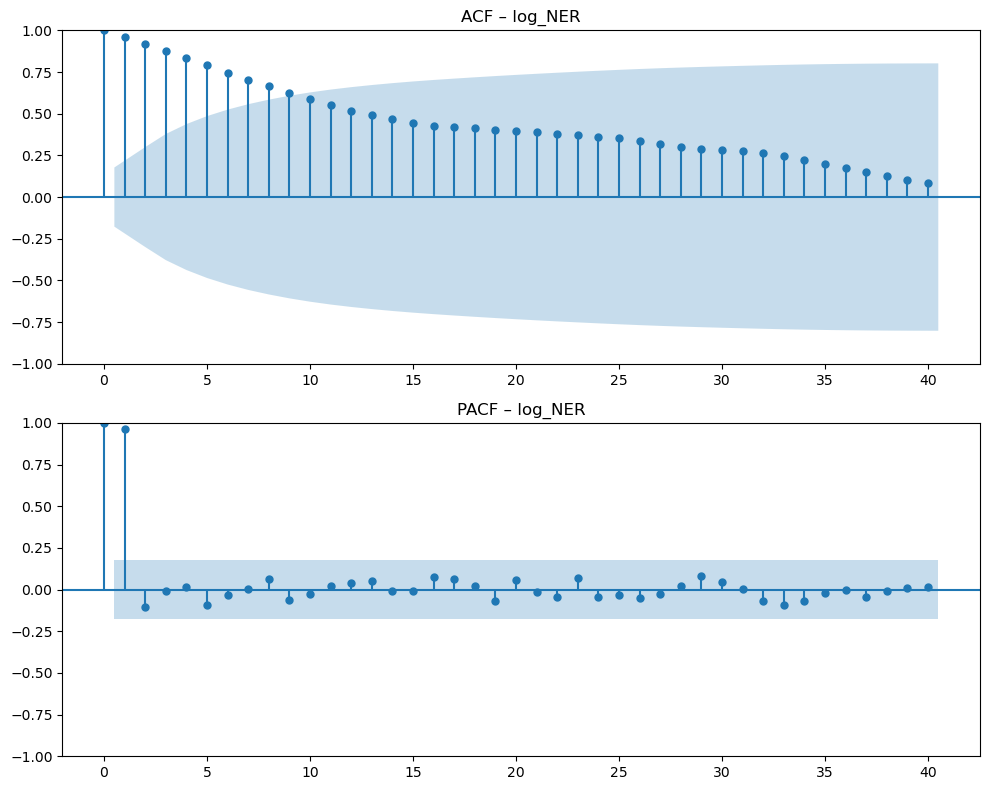

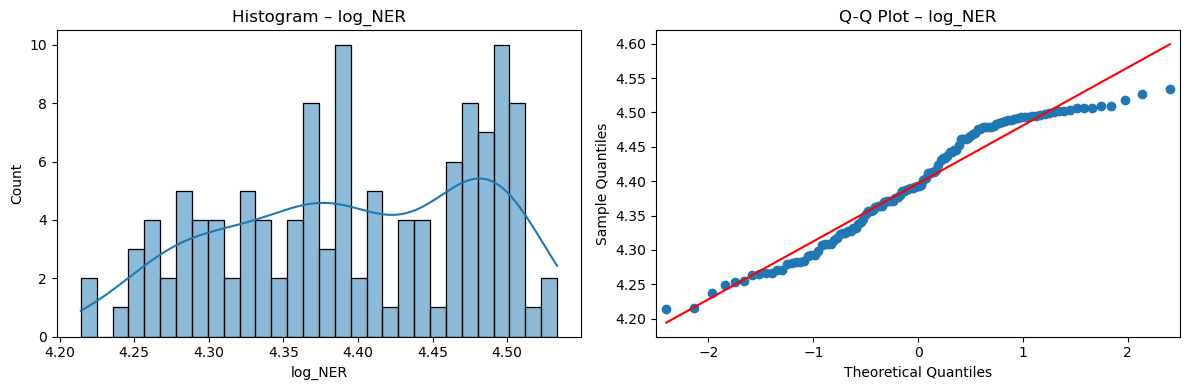

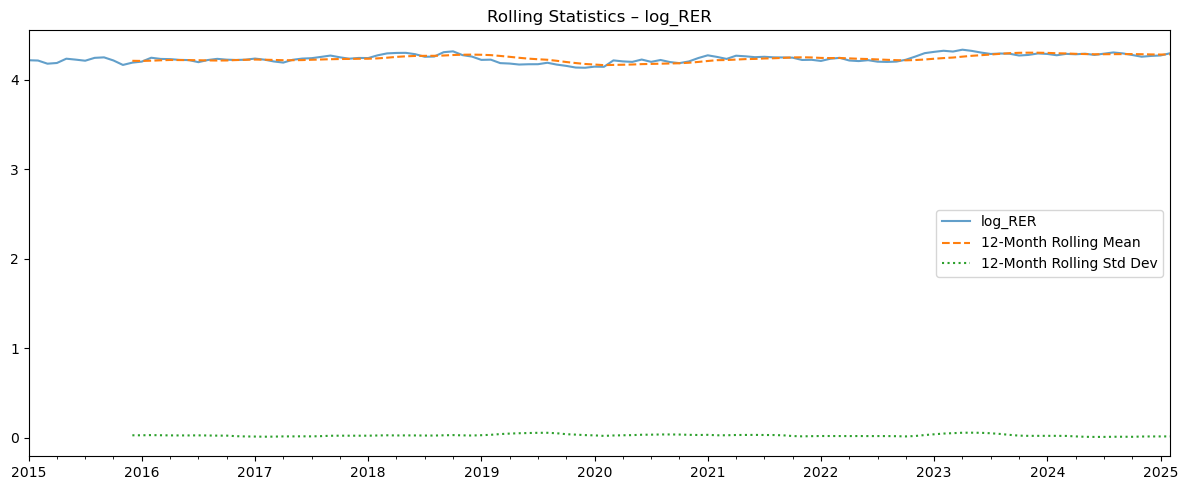

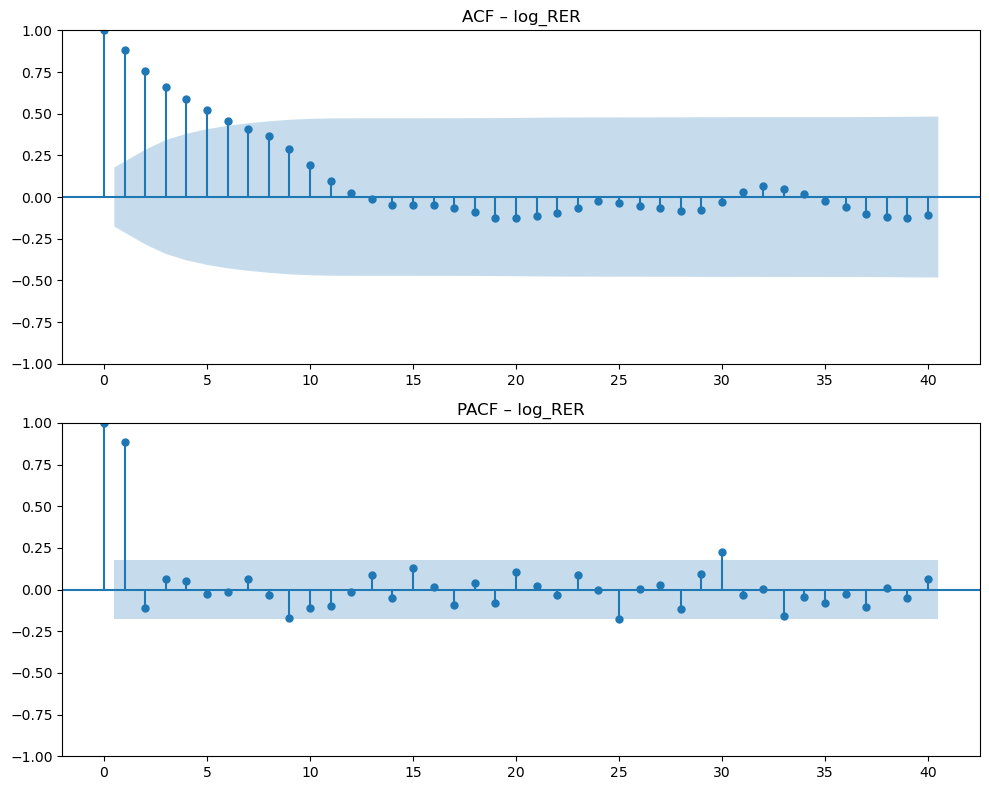

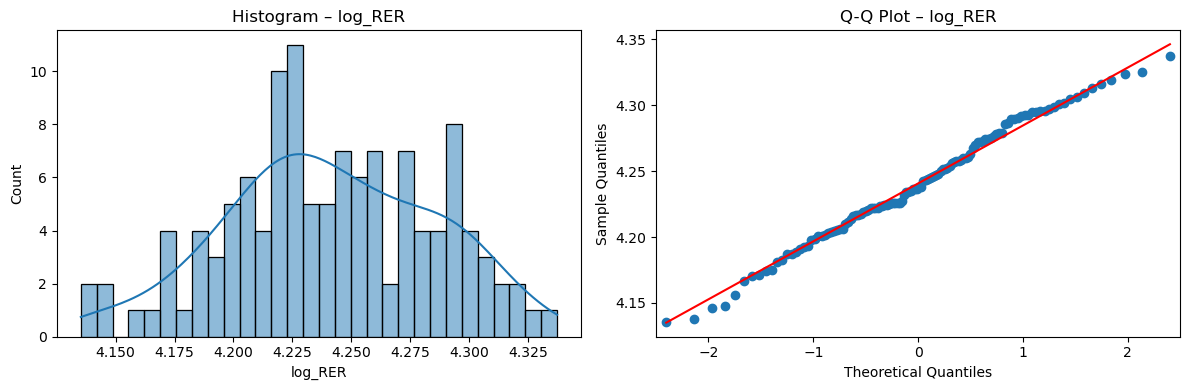

In [18]:
def analyze (series, title):
    plt.style.use("default")

    plt.figure(figsize=(12, 5))
    series.plot(label=title, alpha=0.7)
    series.rolling(12).mean().plot(label='12-Month Rolling Mean', linestyle='--')
    series.rolling(12).std().plot(label='12-Month Rolling Std Dev', linestyle=':')
    plt.title(f'Rolling Statistics – {title}')
    plt.legend()
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(2, 1, figsize=(10, 8))
    plot_acf(series, ax=ax[0], lags=40)
    plot_pacf(series, ax=ax[1], lags=40)
    ax[0].set_title(f'ACF – {title}')
    ax[1].set_title(f'PACF – {title}')
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    sns.histplot(series, kde=True, bins=30)
    plt.title(f'Histogram – {title}')

    plt.subplot(1, 2, 2)
    qqplot(series, line='s', ax=plt.gca())
    plt.title(f'Q-Q Plot – {title}')
    plt.tight_layout()
    plt.show()


analyze(df2['log_CPI_India'], "log_CPI_India")
analyze(df2['log_CPI_Germany'], "log_CPI_Germany")
analyze(df2['log_NER'], "log_NER")
analyze(df2['log_RER'], "log_RER")

##  Absolute PPP test(without differencing)

In [19]:
import statsmodels.api as sm
df2['PPP_abs_theory'] = df2['log_CPI_India'] - df2['log_CPI_Germany']
X_abs = sm.add_constant(df2['PPP_abs_theory'])
y_abs = df2['log_NER']
model_abs = sm.OLS(y_abs, X_abs).fit()

In [20]:
model_abs.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                log_NER   R-squared:                       0.729
Model:                            OLS   Adj. R-squared:                  0.726
Method:                 Least Squares   F-statistic:                     322.2
Date:                Fri, 11 Apr 2025   Prob (F-statistic):           8.80e-36
Time:                        12:42:13   Log-Likelihood:                 208.23
No. Observations:                 122   AIC:                            -412.5
Df Residuals:                     120   BIC:                            -406.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==================================================================================
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              4.2361      0.010    432.134      0.000       4.217       4.256
PPP_abs_theory     1.0292      0.057     17.949      0.000       0.916       1.143
==============================================================================
Omnibus:                        1.278   Durbin-Watson:                   0.223
Prob(Omnibus):                  0.528   Jarque-Bera (JB):                1.252
Skew:                          -0.135   Prob(JB):                        0.535
Kurtosis:                       2.583   Cond. No.                         14.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

##  Relative PPP test(without differencing)

In [21]:
df2['d_log_CPI_India'] = df2['log_CPI_India'].diff()      #(inflation rates)
df2['d_log_CPI_Germany'] = df2['log_CPI_Germany'].diff()
df2['d_log_NER'] = df2['log_NER'].diff()

df2['inflation_diff'] = df2['d_log_CPI_India'] - df2['d_log_CPI_Germany']

In [22]:
df2.isna().sum()

CPI_Germany                  0
CPI_India                    0
Exchange_Rate_INR_per_EUR    0
RER                          0
log_CPI_India                0
log_CPI_Germany              0
log_NER                      0
log_RER                      0
PPP_abs_theory               0
d_log_CPI_India              1
d_log_CPI_Germany            1
d_log_NER                    1
inflation_diff               1
dtype: int64

In [23]:
rel_ppp_df = df2.dropna(subset=['d_log_NER', 'inflation_diff'])   #dropping the NA values

X_rel = sm.add_constant(rel_ppp_df['inflation_diff'])
y_rel = rel_ppp_df['d_log_NER']
model_rel = sm.OLS(y_rel, X_rel).fit()

In [24]:
model_rel.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              d_log_NER   R-squared:                       0.013
Model:                            OLS   Adj. R-squared:                  0.005
Method:                 Least Squares   F-statistic:                     1.588
Date:                Fri, 11 Apr 2025   Prob (F-statistic):              0.210
Time:                        12:42:13   Log-Likelihood:                 316.97
No. Observations:                 121   AIC:                            -629.9
Df Residuals:                     119   BIC:                            -624.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==================================================================================
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              0.0017      0.002      1.035      0.303      -0.002       0.005
inflation_diff     0.1603      0.127      1.260      0.210      -0.092       0.412
==============================================================================
Omnibus:                        8.792   Durbin-Watson:                   1.816
Prob(Omnibus):                  0.012   Jarque-Bera (JB):                8.583
Skew:                           0.589   Prob(JB):                       0.0137
Kurtosis:                       3.562   Cond. No.                         78.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## checking through adf and KPSS tests whether data is stationary

In [25]:
def run_stationarity_tests(series, name):
    print(f"\n{name}:")
    adf_result = adfuller(series)   #adf test
    print(f"  ADF Test: p-value = {adf_result[1]:.4f} => {'Stationary' if adf_result[1] < 0.05 else 'Non-stationary'}")
    try:
        kpss_result = kpss(series, nlags="auto")   #KPSS test
        print(f"  KPSS Test: p-value = {kpss_result[1]:.4f} => {'Stationary' if kpss_result[1] > 0.05 else 'Non-stationary'}")
    except:
        print("  KPSS Test: failed (likely due to insufficient data)")
run_stationarity_tests(df2['log_CPI_India'], "log_CPI_India")
run_stationarity_tests(df2['log_CPI_Germany'], "log_CPI_Germany")
run_stationarity_tests(df2['log_NER'], "log_NER")
run_stationarity_tests(df2['log_RER'], "log_RER")


log_CPI_India:
  ADF Test: p-value = 0.9295 => Non-stationary
  KPSS Test: p-value = 0.0100 => Non-stationary

log_CPI_Germany:
  ADF Test: p-value = 0.9354 => Non-stationary
  KPSS Test: p-value = 0.0100 => Non-stationary

log_NER:
  ADF Test: p-value = 0.6708 => Non-stationary
  KPSS Test: p-value = 0.0100 => Non-stationary

log_RER:
  ADF Test: p-value = 0.1182 => Non-stationary
  KPSS Test: p-value = 0.0363 => Non-stationary


C:\Users\Dell\AppData\Local\Temp\ipykernel_19856\1022942096.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_result = kpss(series, nlags="auto")   #KPSS test
C:\Users\Dell\AppData\Local\Temp\ipykernel_19856\1022942096.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_result = kpss(series, nlags="auto")   #KPSS test
C:\Users\Dell\AppData\Local\Temp\ipykernel_19856\1022942096.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_result = kpss(series, nlags="auto")   #KPSS test


## First order differencing

In [26]:
diff_df = df2[['log_CPI_India', 'log_CPI_Germany', 'log_NER', 'log_RER']].diff().dropna()

## Re-test

In [27]:
for col in diff_df.columns:
    print(f"{col}:")
    adf_p = adfuller(diff_df[col])[1]   #re adf tests
    print(f"  ADF p-value: {adf_p:.4f} → {'Stationary' if adf_p < 0.05 else 'Non-stationary'}")
    
    try:    #re KPSS test 
        kpss_p = kpss(diff_df[col], nlags='auto')[1]
        print(f"  KPSS p-value: {kpss_p:.4f} → {'Stationary' if kpss_p > 0.05 else 'Non-stationary'}")
    except:
        print("  KPSS failed (likely due to too few data points)")
    
    print()

log_CPI_India:
  ADF p-value: 0.0171 → Stationary
  KPSS p-value: 0.1000 → Stationary

log_CPI_Germany:
  ADF p-value: 0.0140 → Stationary
  KPSS p-value: 0.1000 → Stationary

log_NER:
  ADF p-value: 0.0000 → Stationary
  KPSS p-value: 0.1000 → Stationary

log_RER:
  ADF p-value: 0.0000 → Stationary
  KPSS p-value: 0.1000 → Stationary



C:\Users\Dell\AppData\Local\Temp\ipykernel_19856\1379959591.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_p = kpss(diff_df[col], nlags='auto')[1]
C:\Users\Dell\AppData\Local\Temp\ipykernel_19856\1379959591.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_p = kpss(diff_df[col], nlags='auto')[1]
C:\Users\Dell\AppData\Local\Temp\ipykernel_19856\1379959591.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_p = kpss(diff_df[col], nlags='auto')[1]
C:\Users\Dell\AppData\Local\Temp\ipykernel_19856\1379959591.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the


In [28]:
## t test and q test on the models

## trying models based on the test

In [29]:
import warnings
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy.stats import t

warnings.filterwarnings("ignore")

diff_log_RER = df2['log_RER']

model_orders = [
    (1,1,0),
    (1,1,1),
    (2,1,0),
    (2,1,1),
    (2,1,2),
    (1,1,2),
    (1,0,0),
    (0,0,1),
    (1,0,1)
]

alpha = 0.05

for order in model_orders:
    print(f"Model ARIMA{order}")
    
    try:
        model = ARIMA(diff_log_RER, order=order)
        result = model.fit()

        # Compute t-critical based on degrees of freedom
        n = result.nobs
        k = len(result.params)
        df = n - k
        t_critical = t.ppf(1 - alpha / 2, df)
        
        print(f"  t-critical (df={df}): {t_critical:.2f}")

        # t-test check for each parameter
        print("  Coefficient t-values and significance:")
        for name, tval in result.tvalues.items():
            is_significant = abs(tval) > t_critical
            print(f"   {name}: t = {tval:.2f} → {'Significant' if is_significant else 'Not Significant'}")

        # Overall model t-test pass only if all terms are significant
        all_significant = all(abs(tval) > t_critical for tval in result.tvalues[1:])  # excluding intercept if present
        print(f"  Overall t-test pass: {'Yes' if all_significant else 'No'}")

        # Ljung-Box Q-test for residuals
        q_test = acorr_ljungbox(result.resid, lags=[10], return_df=True)
        q_pval = q_test['lb_pvalue'].values[0]
        print(f"  Ljung-Box Q-test p-value: {q_pval:.4f}")
        print(f"  Q-test pass: {'Yes' if q_pval > 0.05 else 'No'}")

        # Model fit criteria
        print(f"  AIC: {result.aic:.2f}")
        print(f"  BIC: {result.bic:.2f}")
        
    except Exception as e:
        print("  Model fitting failed:", e)
    
    print("-" * 30)

Model ARIMA(1, 1, 0)
  t-critical (df=120): 1.98
  Coefficient t-values and significance:
   ar.L1: t = 0.73 → Not Significant
   sigma2: t = 8.58 → Significant
  Overall t-test pass: Yes
  Ljung-Box Q-test p-value: 1.0000
  Q-test pass: Yes
  AIC: -592.68
  BIC: -587.09
------------------------------
Model ARIMA(1, 1, 1)
  t-critical (df=119): 1.98
  Coefficient t-values and significance:
   ar.L1: t = -0.61 → Not Significant
   ma.L1: t = 0.80 → Not Significant
   sigma2: t = 8.73 → Significant
  Overall t-test pass: No
  Ljung-Box Q-test p-value: 1.0000
  Q-test pass: Yes
  AIC: -591.57
  BIC: -583.19
------------------------------
Model ARIMA(2, 1, 0)
  t-critical (df=119): 1.98
  Coefficient t-values and significance:
   ar.L1: t = 0.81 → Not Significant
   ar.L2: t = -1.75 → Not Significant
   sigma2: t = 8.81 → Significant
  Overall t-test pass: No
  Ljung-Box Q-test p-value: 1.0000
  Q-test pass: Yes
  AIC: -593.48
  BIC: -585.09
------------------------------
Model ARIMA(2, 1,

## selected models based on best fit, and now forecasting the result

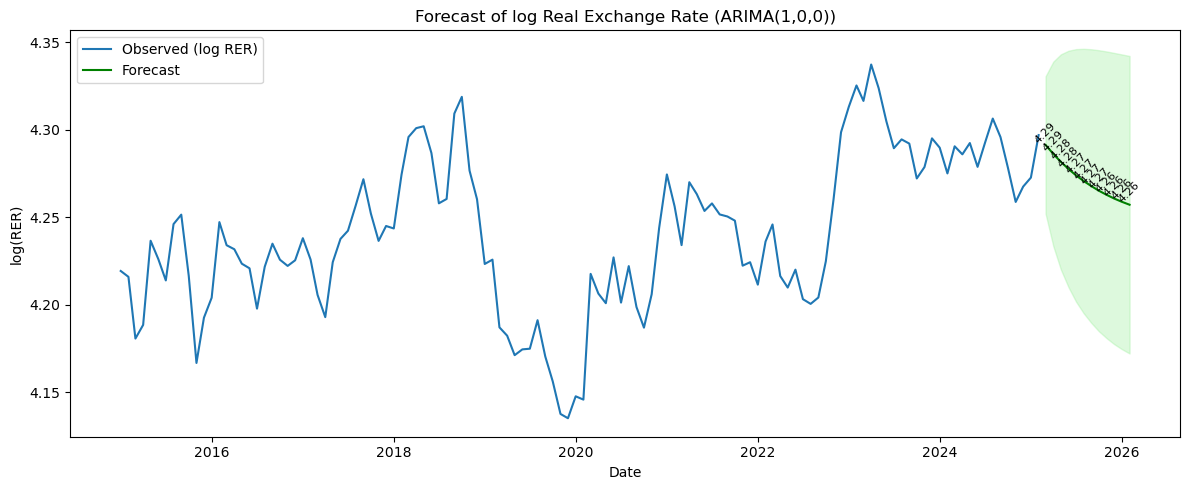

In [30]:
model_final = ARIMA(df2['log_RER'], order=(1, 0, 0))
result_final = model_final.fit()

forecast_steps = 12
forecast = result_final.get_forecast(steps=forecast_steps)
forecast_mean = forecast.predicted_mean
conf_int = forecast.conf_int()

forecast_index = pd.date_range(start=df2.index[-1] + pd.DateOffset(months=1),
                               periods=forecast_steps, freq='MS')

plt.figure(figsize=(12, 5))
plt.plot(df2.index, df2['log_RER'], label='Observed (log RER)')
plt.plot(forecast_index, forecast_mean, label='Forecast', color='green')
plt.fill_between(forecast_index, conf_int.iloc[:, 0], conf_int.iloc[:, 1],
                 color='lightgreen', alpha=0.3)

for date, value in zip(forecast_index, forecast_mean):
    plt.text(date, value, f'{value:.2f}', fontsize=8, ha='center', va='bottom', rotation=45)


plt.title('Forecast of log Real Exchange Rate (ARIMA(1,0,0))')
plt.xlabel('Date')
plt.ylabel('log(RER)')
plt.legend()
plt.tight_layout()
plt.show()

## Validation with Holt's Linear Trend model)

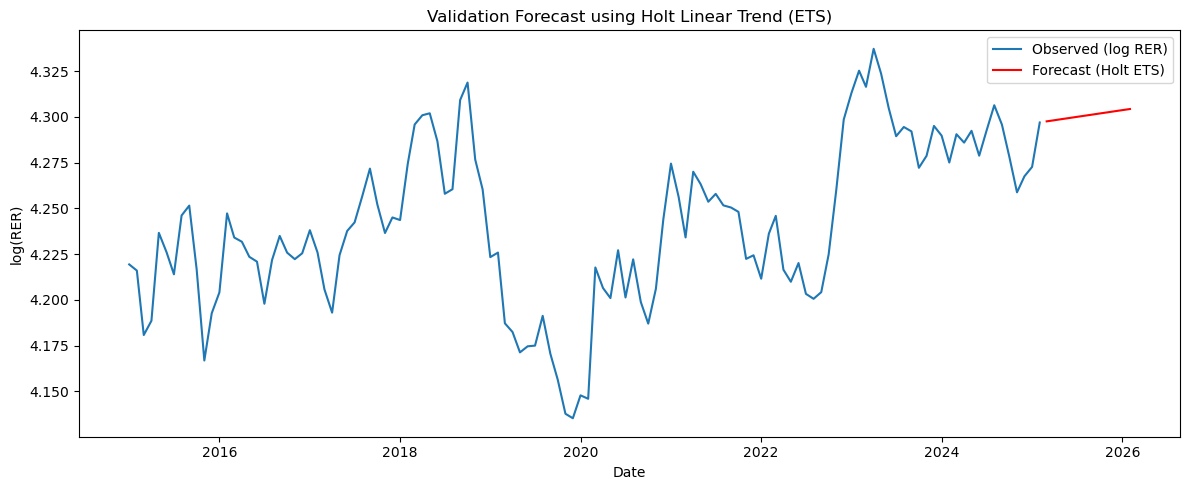

In [31]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

ets_model = ExponentialSmoothing(df2['log_RER'], trend='add', seasonal=None)
ets_fit = ets_model.fit()

ets_forecast = ets_fit.forecast(12)


forecast_index = pd.date_range(start=df2.index[-1] + pd.DateOffset(months=1),
                               periods=12, freq='MS')

plt.figure(figsize=(12, 5))
plt.plot(df2.index, df2['log_RER'], label='Observed (log RER)')
plt.plot(forecast_index, ets_forecast, label='Forecast (Holt ETS)', color='red')
plt.title('Validation Forecast using Holt Linear Trend (ETS)')
plt.xlabel('Date')
plt.ylabel('log(RER)')
plt.legend()
plt.tight_layout()
plt.show()